# Part D · The e-commerce review figure

**Ali Afzal** · BSAI-7B-102 · Data Visualization · Week 4

Leadership's Monday dashboard plots traffic raw, so the weekend rhythm drowns the trend, and shows the
catalogue as a multi-slice 3-D pie. This notebook finds the faults in the two files, states a rule for
each, and builds one 2×2 figure exported at 300 dpi to [`charts/partD_figure.png`](charts/partD_figure.png).

In [1]:
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import squarify
from matplotlib.patches import Rectangle

import sessions_clean
import tslib
from vizlib import PALETTE, save_fig, style_defaults

DATA = Path("data")
CHARTS = Path("charts")
CHARTS.mkdir(exist_ok=True)
style_defaults(dpi=100)
plt.rcParams["date.converter"] = "concise"
BLUE, ORANGE, GREEN = PALETTE["series"]
PINK = PALETTE["series_4th"]
GREY, INK, SOFT = PALETTE["muted"], PALETTE["ink"], PALETTE["ink_soft"]

## 1 · Find the faults before plotting anything

The four calls from the brief, in order.

In [2]:
raw = pd.read_csv(DATA / "sessions_hourly.csv")
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 12670 entries, 0 to 12669
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   ts           12670 non-null  str  
 1   sessions     12670 non-null  int64
 2   orders       12670 non-null  int64
 3   revenue_pkr  12670 non-null  int64
 4   device       12670 non-null  str  
dtypes: int64(3), str(2)
memory usage: 495.1 KB


In [3]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
sessions,12670.0,947.951381,646.882994,-1.0,435.0,756.0,1368.00,9811.0
orders,12670.0,30.016732,20.089492,4.0,14.0,24.0,42.00,304.0
revenue_pkr,12670.0,132564.968824,100150.706234,10350.0,58036.5,102359.0,182232.25,1652881.0


In [4]:
raw.device.value_counts()

device
Mobile     6994
Desktop    3452
mobile      883
Tablet      777
desktop     318
MOBILE      246
Name: count, dtype: int64

In [5]:
raw.ts.head(10).tolist()

['2024-04-29 11:00:00',
 '2024-10-26 05:00:00',
 '2025-08-04 20:00:00',
 '2024-10-05 19:00:00',
 '2025-01-22 20:00:00',
 '05/10/2024 09:00',
 '2024-08-11 15:00:00',
 '12/04/2025 10:00',
 '2024-07-24 02:00:00',
 '2025-03-27 11:00:00']

Four faults are visible in that output alone:

1. **Two timestamp formats.** `ts` is text, and the head shows both `2024-04-29 11:00:00` and
   `05/10/2024 09:00`.
2. **Rows out of order.** The first ten timestamps jump between 2024 and 2025.
3. **Device labels.** `Mobile`, `mobile` and `MOBILE ` (with a trailing space) are one device. So are
   `Desktop` and `desktop`.
4. **A sentinel.** `sessions` has a minimum of **−1**. Nobody visits −1 times, so this is a logger's
   "no reading".

The other two only appear once the index is a real `DatetimeIndex`, so I parse first and audit second.

In [6]:
hourly = sessions_clean.load_hourly()
log = sessions_clean.LOG
print(f"ISO rows {log['n_iso']:,}, day-first rows {log['n_dayfirst']:,}, unparsed {log['n_unparsed']}")
print(f"true span:          {log['true_span']}")
print(f"format='mixed' span: {log['mixed_span']}  <- {log['mixed_rows_moved']:,} rows silently moved")

ISO rows 9,019, day-first rows 3,651, unparsed 0
true span:          ('2024-04-01 00:00:00', '2025-09-11 23:00:00')
format='mixed' span: ('2024-01-04 01:00:00', '2025-12-08 22:00:00')  <- 1,382 rows silently moved


**The parse trap.** `pd.to_datetime(df.ts)` guesses ISO and fails on the first slash row. With
`format="mixed"` it parses every row, raises nothing, and loses nothing, but it reads `05/10/2024` as **5
October** instead of 10 May. That moves 1,382 rows and stretches the series to start on 4 *January* 2024,
three months before the platform's April 2024 start. The row count is identical either way. Only checking
`.min()` and `.max()` catches it.

My rule: each format is parsed with an explicit pattern, `%Y-%m-%d %H:%M:%S` for ISO and `%d/%m/%Y %H:%M`
for the slash rows. Day-first isn't a guess: 59% of the slash rows have a first field above 12, which
can only be a day, and Pakistan writes dates day-first.

In [7]:
audit = tslib.audit_index(hourly, "h")
print(f"after parse: duplicated hours {log['n_duplicate_rows']} (copies that disagree: {log['duplicates_disagree']}), "
      f"missing hours {log['n_missing_hours']}")
print("whole days never recorded:", log["missing_days"])

after parse: duplicated hours 286 (copies that disagree: 0), missing hours 312
whole days never recorded: ['2024-05-18', '2024-07-02', '2024-07-03', '2024-09-27', '2024-11-11', '2024-12-25', '2025-01-01', '2025-02-14', '2025-03-30', '2025-03-31', '2025-06-07', '2025-07-19', '2025-08-23']


The two faults that only a `DatetimeIndex` shows:

5. **Duplicated hours: 286.** The same hour was written by both loggers, once in each format. All 286
   copies agree on every value, so dropping one copy loses nothing.
6. **Missing hours: 312.** That's exactly **13 whole days** of 24 hours (5/18, 7/2–3, 9/27, 11/11, 12/25,
   1/1, 2/14, 3/30–31, 6/7, 7/19, 8/23). The collector was down. These days aren't filled. They stay NaN,
   and the line breaks.

And the fact from the data dictionary: the extract stops on **11 September 2025**, 11 days into a
30-day month. The figure ends on 31 August so no partial period is shown.

### Every rule, with its count

In [8]:
daily = sessions_clean.load_daily()
rules = pd.DataFrame([
    ("Two timestamp formats", "parse each with an explicit format; day-first for slashes",
     f"{log['n_dayfirst']:,} rows day-first", "0 rows lost; format='mixed' would move 1,382"),
    ("Rows unsorted", "sort by parsed timestamp", "12,670 rows", "order only"),
    ("Device label case/space", "strip + title case", "6 labels", "3 labels: Mobile 8,123, Desktop 3,770, Tablet 777"),
    ("Duplicated hours", "drop the second copy (copies identical)", f"{log['n_duplicate_rows']} rows",
     f"12,670 -> {log['n_clean_hours']:,} rows"),
    ("Sentinel sessions = -1", "set to NaN, excluded from the day's sum", f"{log['n_sentinel']} hours",
     f"{log['n_days_short']} days summed from 21-23 hours"),
    ("Missing hours", "left missing; daily sum(min_count=1) -> NaN", f"{log['n_missing_hours']} hours",
     f"{log['n_days_missing']} days shown as gaps"),
    ("Partial final month", "end the series on 2025-08-31", f"{log['n_days_after_cut']} days", f"{log['n_days']} days kept"),
], columns=["fault", "rule", "affected", "effect"])
rules

,fault,rule,affected,effect
0,Two timestamp formats,parse each with an explicit format; day-first ...,"3,651 rows day-first","0 rows lost; format='mixed' would move 1,382"
1,Rows unsorted,sort by parsed timestamp,"12,670 rows",order only
2,Device label case/space,strip + title case,6 labels,"3 labels: Mobile 8,123, Desktop 3,770, Tablet 777"
3,Duplicated hours,drop the second copy (copies identical),286 rows,"12,670 -> 12,384 rows"
4,Sentinel sessions = -1,"set to NaN, excluded from the day's sum",287 hours,222 days summed from 21-23 hours
5,Missing hours,left missing; daily sum(min_count=1) -> NaN,312 hours,13 days shown as gaps
6,Partial final month,end the series on 2025-08-31,11 days,518 days kept


A note on the sentinel rule: a day with a sentinel hour is summed from the 21–23 hours that were recorded,
so it's understated by at most 3/24 of a day. Scaling up instead would invent sessions. Most sentinel
hours fall at night, the 7-day mean dilutes them further, and the Part B Black Friday numbers (113,710
against a 24,612 fortnight median) match the brief exactly under this rule.

## 2 · The catalogue: is it a tree?

In [9]:
cat = pd.read_csv(DATA / "revenue_catalogue.csv")
dupes = cat[cat.sku.duplicated(keep=False)]
print(dupes[["category", "subcategory", "sku", "sku_name", "net_revenue_pkr_m"]].to_string())
neg = cat[cat.net_revenue_pkr_m < 0]
print(f"\nnegative net revenue: {len(neg)} SKUs, {neg.net_revenue_pkr_m.sum():.2f} PKR m")
print(neg.groupby("subcategory").net_revenue_pkr_m.agg(["count", "sum"]).round(3))

            category subcategory       sku sku_name  net_revenue_pkr_m
126  Audio & Imaging       Audio  SKU-0127  AUDI-04            14.8275
344        Lifestyle   Wearables  SKU-0127  AUDI-04            14.8275

negative net revenue: 7 SKUs, -1.07 PKR m
             count    sum
subcategory              
Accessories      1 -0.000
Drones           2 -0.114
Footwear         2 -0.625
Wearables        2 -0.331


- **Duplicate SKU.** `SKU-0127` (`AUDI-04`, an Audio SKU) appears twice, once under Audio & Imaging →
  Audio and once more under Lifestyle → Wearables. A tree needs every child to have exactly one parent.
  **Rule:** keep the first row, the one whose parent matches its `AUDI-` name, and drop the Wearables copy
  (14.83 PKR m that would otherwise be counted twice).
- **Negative net revenue.** 7 SKUs returned more than they sold, −1.07 PKR m in total. Negatives have no
  area. **Rule:** they're left out of the treemap and the bars, and named on the figure with their total.

In [10]:
clean = cat.drop_duplicates("sku", keep="first")
pos = clean[clean.net_revenue_pkr_m > 0]
sub = pos.groupby(["category", "subcategory"]).net_revenue_pkr_m.sum().sort_values(ascending=False)
share = (sub.droplevel(0) / sub.sum() * 100)

target = pd.read_csv(DATA / "shares_eight.csv").set_index("subcategory").share_pct
check = pd.DataFrame({"mine": share.round(2), "shares_eight": target, "diff_pp": (share - target).round(2)})
print(check.sort_values("mine", ascending=False))
print(f"\nlargest gap: {check.diff_pp.abs().max():.2f} pp (the brief allows 0.3)")
assert check.diff_pp.abs().max() < 0.3

raw_share = cat.groupby("subcategory").net_revenue_pkr_m.sum()
print(f"without the fixes, Wearables would be off by {(raw_share / raw_share.sum() * 100 - target)['Wearables']:.2f} pp")

_, other_note = tslib.rollup_other(sub.droplevel(0), min_share_pct=1.0)
print("Other bucket:", other_note)

              mine  shares_eight  diff_pp
subcategory                              
Phones       24.75          24.6     0.15
Laptops      18.22          18.4    -0.18
Audio        14.98          15.0    -0.02
Accessories  13.33          13.1     0.23
Footwear     10.99          11.2    -0.21
Wearables     9.36           9.2     0.16
Cameras       5.97           6.1    -0.13
Drones        2.41           2.4     0.01

largest gap: 0.23 pp (the brief allows 0.3)
without the fixes, Wearables would be off by 0.93 pp
Other bucket: no categories below 1.0%


**Self-check passed:** every sub-category share is within **0.23 pp** of `shares_eight.csv`, and the
unfixed file is out by 0.93 pp on Wearables, just as the brief warns. No sub-category is under 1% (the
smallest, Drones, is 2.4%), so the `Other` bucket is empty. I cut the depth at sub-category: the 336 positive SKUs
underneath aren't drawn.

## 3 · The figure

monthly mean of daily sessions: Apr 2024 15,126, Nov 2024 29,342, Apr 2025 22,427, Aug 2025 28,014
heatmap: busiest (np.int32(6), np.int32(20)) = 2,326, quietest (np.int32(2), np.int32(4)) = 363
banked figsize for the smoothed series (width 9): (9.0, 5.12)


'charts\\partD_figure.png'

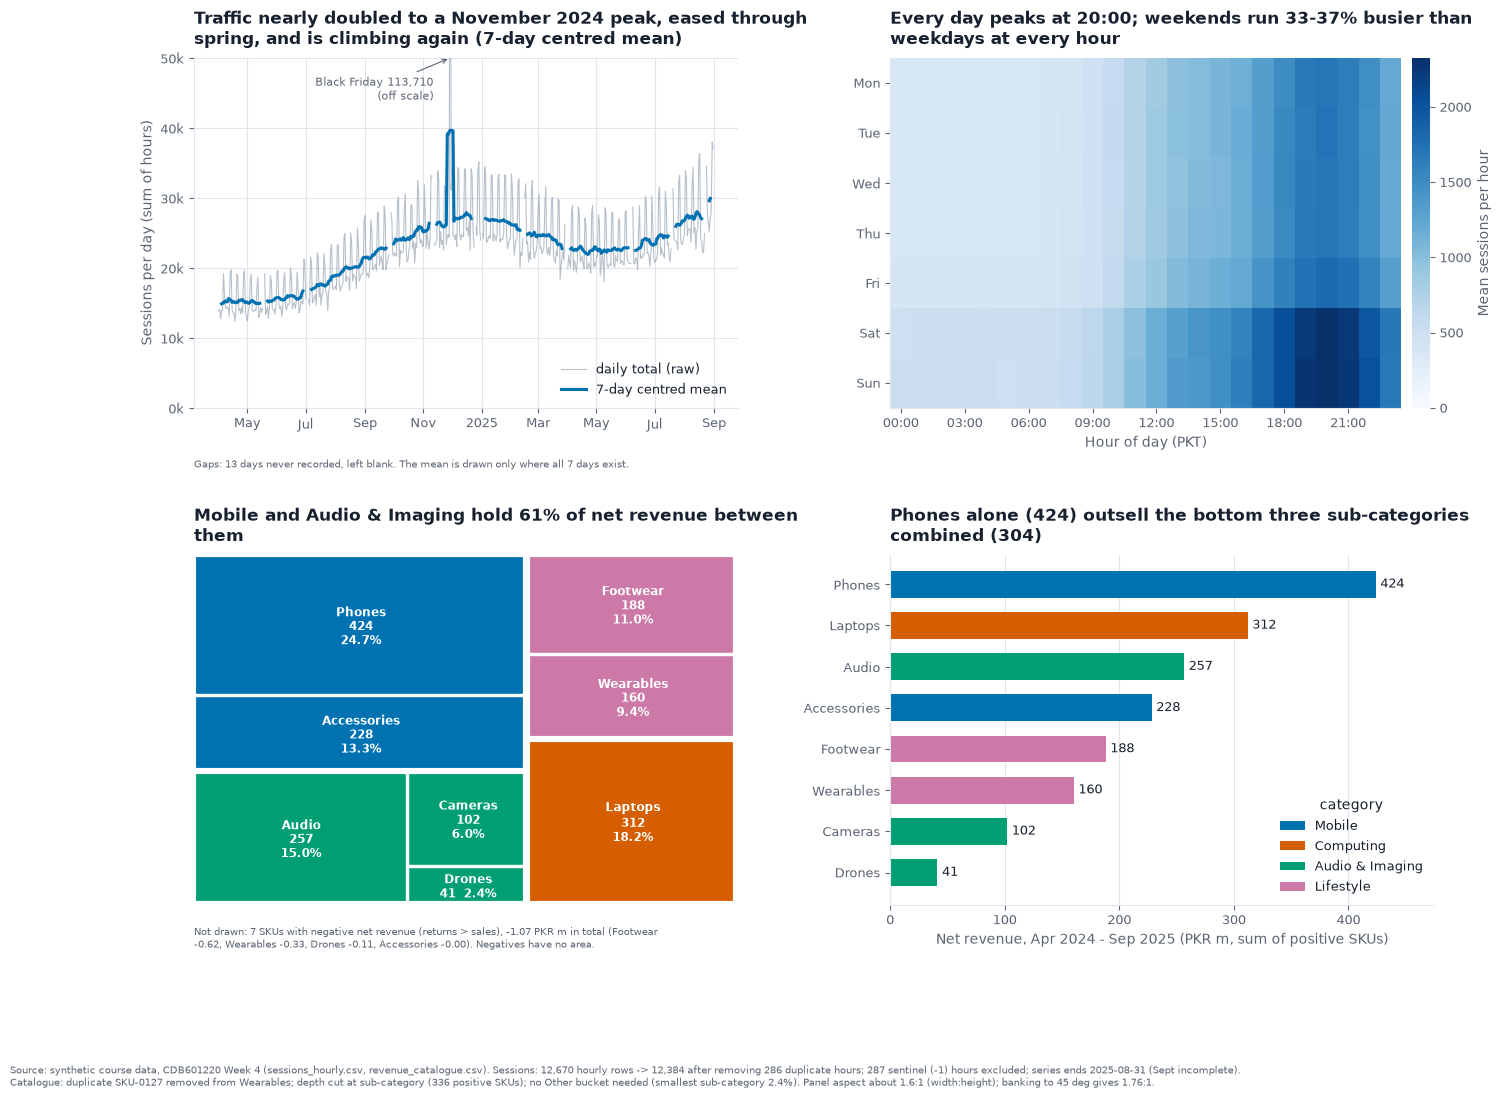

In [11]:
CAT_COLOUR = {"Mobile": BLUE, "Computing": ORANGE, "Audio & Imaging": GREEN, "Lifestyle": PINK}
WINDOW = 7   # fixed before plotting: the cycle being removed is weekly (Part B.1)

smooth = daily.rolling(WINDOW, center=True, min_periods=WINDOW).mean()
hm = (hourly[:sessions_clean.LAST_FULL_DAY + " 23:00"].sessions
      .groupby([hourly[:sessions_clean.LAST_FULL_DAY + " 23:00"].index.dayofweek,
                hourly[:sessions_clean.LAST_FULL_DAY + " 23:00"].index.hour]).mean().unstack())
m = daily.resample("MS").mean()
print(f"monthly mean of daily sessions: Apr 2024 {m.iloc[0]:,.0f}, Nov 2024 {m['2024-11'].iloc[0]:,.0f}, "
      f"Apr 2025 {m['2025-04'].iloc[0]:,.0f}, Aug 2025 {m.iloc[-1]:,.0f}")
print(f"heatmap: busiest {hm.stack().idxmax()} = {hm.stack().max():,.0f}, quietest {hm.stack().idxmin()} = {hm.stack().min():,.0f}")
print("banked figsize for the smoothed series (width 9):", tuple(round(v, 2) for v in tslib.banked_figsize(smooth.to_numpy())))


def nested_treemap(ax, sub, colours, x=0, y=0, w=100, h=100, pad=0.5):
    """Categories first, then each category's sub-categories inside its block, so containment is real."""
    tops = sub.groupby(level=0).sum().sort_values(ascending=False)
    for (name, val), r in zip(tops.items(), squarify.squarify(squarify.normalize_sizes(tops.values, w, h), x, y, w, h)):
        kids = sub[name].sort_values(ascending=False)
        for (kid, kv), k in zip(kids.items(), squarify.squarify(
                squarify.normalize_sizes(kids.values, r["dx"], r["dy"]), r["x"], r["y"], r["dx"], r["dy"])):
            ax.add_patch(Rectangle((k["x"], k["y"]), k["dx"] - pad, k["dy"] - pad, fc=colours[name], ec="white", lw=1))
            sep = "\n" if k["dy"] > 12 else "  "   # thin blocks get a one-line label
            ax.text(k["x"] + k["dx"] / 2, k["y"] + k["dy"] / 2, f"{kid}\n{kv:,.0f}{sep}{kv / sub.sum():.1%}",
                    ha="center", va="center", color="white", fontsize=8.5, fontweight="bold", linespacing=1.2)
        ax.add_patch(Rectangle((r["x"], r["y"]), r["dx"] - pad, r["dy"] - pad, fill=False, ec="white", lw=3))
    ax.set_xlim(0, 100)
    ax.set_ylim(100, 0)
    ax.axis("off")


fig, axes = plt.subplots(2, 2, figsize=(16, 11), gridspec_kw=dict(hspace=0.42, wspace=0.28))
(p1, p2), (p3, p4) = axes

# Panel 1: raw daily in light grey, the 7-day centred mean on top
p1.plot(daily.index, daily.values, color=GREY, lw=0.8, alpha=0.7, label="daily total (raw)")
p1.plot(smooth.index, smooth.values, color=BLUE, lw=2.2, label=f"{WINDOW}-day centred mean")
p1.set_ylim(0, 50_000)
bf = pd.Timestamp("2024-11-29")
p1.annotate(f"Black Friday {daily[bf]:,.0f}\n(off scale)", (bf, 50_000), xytext=(-12, -30),
            textcoords="offset points", ha="right", fontsize=8, color=SOFT,
            arrowprops=dict(arrowstyle="->", color=SOFT, lw=0.8))
p1.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
p1.set_ylabel("Sessions per day (sum of hours)")
p1.legend(loc="lower right")
p1.set_title(textwrap.fill("Traffic nearly doubled to a November 2024 peak, eased through spring, "
                           f"and is climbing again ({WINDOW}-day centred mean)", 62))
p1.text(0, -0.17, f"Gaps: {log['n_days_missing']} days never recorded, left blank. "
        "The mean is drawn only where all 7 days exist.", transform=p1.transAxes, fontsize=7.5, color=SOFT)

# Panel 2: day-of-week x hour heatmap, sequential
im = p2.imshow(hm.values, aspect="auto", cmap=PALETTE["sequential"], vmin=0)
p2.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
p2.set_xticks(range(0, 24, 3), [f"{h:02d}:00" for h in range(0, 24, 3)])
p2.grid(False)
p2.set_xlabel("Hour of day (PKT)")
cb = fig.colorbar(im, ax=p2, fraction=0.04, pad=0.02)
cb.set_label("Mean sessions per hour", color=SOFT)
cb.outline.set_visible(False)
lift = (hm.loc[5:6].mean() / hm.loc[0:4].mean() - 1) * 100
p2.set_title(textwrap.fill(f"Every day peaks at 20:00; weekends run {lift.min():.0f}-{lift.max():.0f}% busier than weekdays at every hour", 62))

# Panel 3: nested treemap, one hue per parent category
nested_treemap(p3, sub, CAT_COLOUR)
top2 = sub.groupby(level=0).sum().nlargest(2)
p3.set_title(textwrap.fill(f"{top2.index[0]} and {top2.index[1]} hold {top2.sum() / sub.sum():.0%} of net revenue between them", 62))
neg_txt = ", ".join(f"{k} {v:.2f}" for k, v in neg.groupby("subcategory").net_revenue_pkr_m.sum().sort_values().items())
p3.text(0, -0.06, textwrap.fill(f"Not drawn: {len(neg)} SKUs with negative net revenue (returns > sales), "
                                f"{neg.net_revenue_pkr_m.sum():.2f} PKR m in total ({neg_txt}). Negatives have no area.", 95),
        transform=p3.transAxes, fontsize=7.5, color=SOFT, va="top")

# Panel 4: the same sub-categories as sorted bars, values printed
bars = sub.sort_values()
names = bars.index.get_level_values(1)
p4.barh(names, bars.values, color=[CAT_COLOUR[c] for c in bars.index.get_level_values(0)], height=0.65)
for i, v in enumerate(bars.values):
    p4.text(v + 4, i, f"{v:,.0f}", va="center", fontsize=9)
p4.set_xlim(0, bars.max() * 1.12)
p4.set_xlabel("Net revenue, Apr 2024 - Sep 2025 (PKR m, sum of positive SKUs)")
p4.grid(axis="y", visible=False)
for c, col in CAT_COLOUR.items():
    p4.barh([0], [0], color=col, label=c)
p4.legend(loc="lower right", title="category")
p4.set_title(textwrap.fill(f"Phones alone ({bars.iloc[-1]:,.0f}) outsell the bottom three sub-categories combined "
                           f"({bars.iloc[:3].sum():,.0f})", 62))

save_fig(fig, CHARTS / "partD_figure.png", note=(
    "Source: synthetic course data, CDB601220 Week 4 (sessions_hourly.csv, revenue_catalogue.csv). "
    f"Sessions: {log['n_raw_rows']:,} hourly rows -> {log['n_clean_hours']:,} after removing {log['n_duplicate_rows']} duplicate hours; "
    f"{log['n_sentinel']} sentinel (-1) hours excluded; series ends 2025-08-31 (Sept incomplete).\n"
    "Catalogue: duplicate SKU-0127 removed from Wearables; depth cut at sub-category (336 positive SKUs); no Other bucket needed "
    "(smallest sub-category 2.4%). Panel aspect about 1.6:1 (width:height); banking to 45 deg gives 1.76:1."))

**The aspect ratio.** `banked_figsize` on the 7-day mean, at width 9, asks for a height of 5.12, which
is **1.76:1**. Each panel here is about 1.6:1 (width:height), so slopes are drawn slightly steeper than
the 45° ideal, by about 10%. I kept 1.6:1 so the four panels share one grid, and the number is stated on
the figure rather than left implicit.

## Appendix · The same panel with a 28-day window

The window was fixed at 7 days before plotting. This appendix checks that a longer window doesn't change
the direction of anything the title claims.

,7-day,28-day
peak month,Nov 2024,Dec 2024
spring low,May 2025,Apr 2025
Aug 2025 vs spring low,+22%,+20%
Nov 2024 vs Apr 2024,+90%,+96%


'charts\\partD_appendix_28day.png'

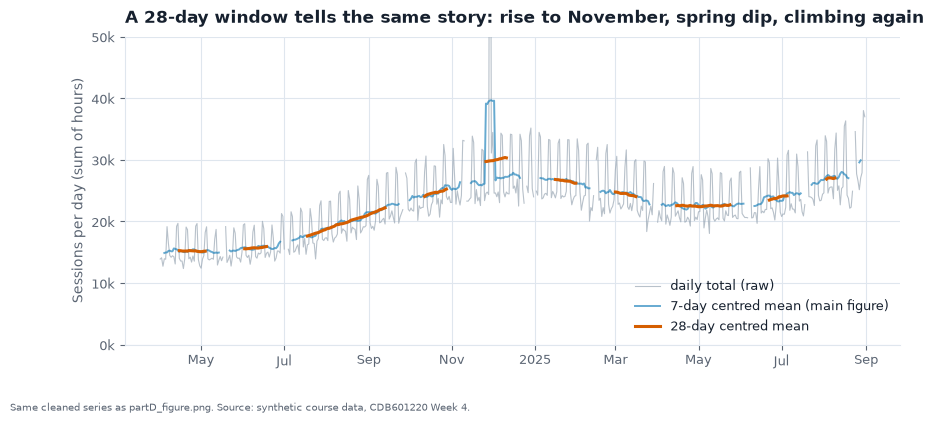

In [12]:
s28 = daily.rolling(28, center=True, min_periods=28).mean()
turns = {}
for name, s in [("7-day", smooth), ("28-day", s28)]:
    mo = s.resample("MS").mean()
    turns[name] = {"peak month": mo.idxmax().strftime("%b %Y"), "spring low": mo["2025"].idxmin().strftime("%b %Y"),
                   "Aug 2025 vs spring low": f"{mo.iloc[-1] / mo['2025'].min() - 1:+.0%}",
                   "Nov 2024 vs Apr 2024": f"{mo['2024-11'].iloc[0] / mo.iloc[0] - 1:+.0%}"}
display(pd.DataFrame(turns))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily.index, daily.values, color=GREY, lw=0.8, alpha=0.7, label="daily total (raw)")
ax.plot(smooth.index, smooth.values, color=BLUE, lw=1.4, alpha=0.6, label="7-day centred mean (main figure)")
ax.plot(s28.index, s28.values, color=ORANGE, lw=2.2, label="28-day centred mean")
ax.set_ylim(0, 50_000)
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
ax.set_ylabel("Sessions per day (sum of hours)")
ax.legend(loc="lower right")
ax.set_title("A 28-day window tells the same story: rise to November, spring dip, climbing again")
save_fig(fig, CHARTS / "partD_appendix_28day.png",
         note="Same cleaned series as partD_figure.png. Source: synthetic course data, CDB601220 Week 4.")